# 03 Baseline Model

---
### 1. Setup Environment


In [4]:
import sys
from pathlib import Path

ROOT_DIR = Path(r"c:\Project\napasloka\napasloka")

if str(ROOT_DIR) not in sys.path:
    sys.path.insert(0, str(ROOT_DIR))

---
### 2. Pemuatan Data Uji & Pembuatan Prediksi Baseline


In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.features.lag_features import create_lag_features
from src.data.clean_data import chronological_train_test_split
from src.utils.metrics import calculate_regression_metrics


STATION_ID = "pantai-makmur"
POLLUTANT = "co2"
SCENARIO = "scenario_2"

df_raw = pd.read_csv(ROOT_DIR / "data" / "processed" / f"jabodetabek_{POLLUTANT}_dataset.csv")
df_raw["datetime"] = pd.to_datetime(df_raw["datetime"], utc=True).dt.tz_convert("Asia/Jakarta")

coord_id = "-6.1_107.0" 
df_station = df_raw[(df_raw["location"] == coord_id) | (df_raw["location"] == STATION_ID)].sort_values("datetime").reset_index(drop=True)
df_features = create_lag_features(df_station, pollutant=POLLUTANT, scenario=SCENARIO, drop_incomplete_rows=True)

_, test_df = chronological_train_test_split(df_features, test_fraction=0.2)

target_col = "carbon_dioxide"
lag1_col = "carbon_dioxide_lag_1h"

# Ground Truth aktual pada waktu t+1
y_true = test_df[target_col].values
# Prediksi Baseline Persistence: memproyeksikan t+1 menggunakan nilai observasi t (lag 1h)
y_baseline = test_df[lag1_col].values

metrics_baseline = calculate_regression_metrics(y_true, y_baseline)

print(" KINERJA NAIVE PERSISTENCE BASELINE MODEL (DATA UJI)")
print(f"MAE  : {metrics_baseline['mae']:.4f} ppm")
print(f"RMSE : {metrics_baseline['rmse']:.4f} ppm")
print(f"MAPE : {metrics_baseline['mape']:.2f}%")
print(f"R²   : {metrics_baseline['r2']:.4f}")


 KINERJA NAIVE PERSISTENCE BASELINE MODEL (DATA UJI)
MAE  : 2.7700 ppm
RMSE : 4.0192 ppm
MAPE : 0.60%
R²   : 0.8979


---
### 3. Visualisasi Hasil Prediksi Baseline vs Aktual


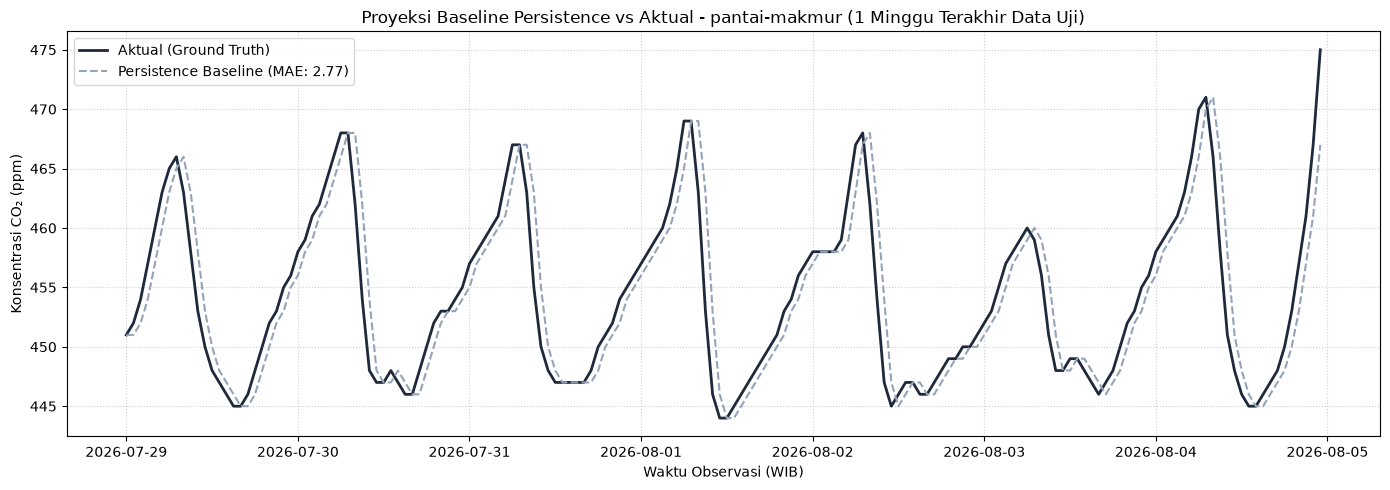

In [6]:
viz_df = test_df.tail(168).copy()  # 1 minggu terakhir data uji

plt.figure(figsize=(14, 5))
plt.plot(viz_df["datetime"], viz_df[target_col], label="Aktual (Ground Truth)", color="#1e293b", linewidth=2)
plt.plot(viz_df["datetime"], viz_df[lag1_col], label=f"Persistence Baseline (MAE: {metrics_baseline['mae']:.2f})", color="#94a3b8", linestyle="--")

plt.title(f"Proyeksi Baseline Persistence vs Aktual - {STATION_ID} (1 Minggu Terakhir Data Uji)", fontsize=12)
plt.xlabel("Waktu Observasi (WIB)")
plt.ylabel("Konsentrasi CO₂ (ppm)")
plt.legend(frameon=True)
plt.grid(True, linestyle=":", alpha=0.6)
plt.tight_layout()
plt.show()
